# 2_generate_bipv_retrofit

This notebook performs the BIPV retrofit visualization stage of the `image2bipv` pipeline.

It reads the rectified facade outputs from notebook `0_dust3r_pipe.ipynb` and the scale predictions from notebook `1_vlm_scale_pred.ipynb`, then:

- builds a facade PV layout using either a manual or automatic strategy
- saves a binary PV mask and a texture-based overlay
- optionally generates a more realistic appearance using either Gemini image editing or ControlNet + SDXL
- optionally reprojects the generated result back to the original perspective
- logs the run configuration and output paths for downstream use

The notebook is organized so the main runtime decisions live in one configuration block:
`LAYOUT_MODE`, `GENERATOR_TYPE`, and `GENERATE_APPEARANCE`.

In [1]:
# Standard library
import os
import sys
import math
from dataclasses import dataclass
from pathlib import Path
from time import perf_counter
from typing import Optional

# Data handling
import numpy as np
import pandas as pd

# Imaging / plotting
import cv2
from PIL import Image
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

In [2]:
# -----------------------------------------------------------------------------
# Repository-relative paths
# -----------------------------------------------------------------------------

REPO_ROOT = Path("..").resolve()

DATA_DIR = REPO_ROOT / "data" / "demo" / "input"
OUTPUT0_DIR = REPO_ROOT / "outputs" / "0_dust3r_outputs"
OUTPUT1_DIR = REPO_ROOT / "outputs" / "1_vlm_preds"
OUTPUT2_DIR = REPO_ROOT / "outputs" / "2_generated_bipv_facades"
ASSETS_DIR = REPO_ROOT / "assets"
EXTERNAL_DIR = REPO_ROOT / "external"

IMAGES_DIR = DATA_DIR / "images"
MASKS_DIR = DATA_DIR / "masks"
RECTIFIED_DIR = OUTPUT0_DIR / "rectified"
RECTIFICATION_RESULTS_CSV = OUTPUT0_DIR / "tables" / "dust3r_rectification_results.csv"
VLM_PREDICTIONS_CSV = OUTPUT1_DIR / "vlm_predictions.csv"

PLOTS_DIR = OUTPUT2_DIR / "plots"
TABLES_DIR = OUTPUT2_DIR / "tables"
CACHE_DIR = OUTPUT2_DIR / "cache"

for folder in [OUTPUT2_DIR, PLOTS_DIR, TABLES_DIR, CACHE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

PV_TEXTURE_PNG = DATA_DIR / "pv_texture.png"
RUN_LOG_CSV = TABLES_DIR / "generation_runtime_log.csv"

print("REPO_ROOT:", REPO_ROOT)
print("RECTIFIED_DIR:", RECTIFIED_DIR)
print("VLM_PREDICTIONS_CSV:", VLM_PREDICTIONS_CSV)
print("OUTPUT2_DIR:", OUTPUT2_DIR)

REPO_ROOT: D:\facade2dim\image2bipv
RECTIFIED_DIR: D:\facade2dim\image2bipv\outputs\0_dust3r_outputs\rectified
VLM_PREDICTIONS_CSV: D:\facade2dim\image2bipv\outputs\1_vlm_preds\vlm_predictions.csv
OUTPUT2_DIR: D:\facade2dim\image2bipv\outputs\2_generated_bipv_facades


In [3]:
# -----------------------------------------------------------------------------
# Runtime configuration
# -----------------------------------------------------------------------------
# Main switches:
# - LAYOUT_MODE: "automatic" or "manual"
# - GENERATOR_TYPE: "controlnet", "gemini", or "none"
# - GENERATE_APPEARANCE: if False, stop after mask + overlay generation
# -----------------------------------------------------------------------------

TARGET_IMAGE_NAME = "151360_0_v1.jpg"

LAYOUT_MODE = "automatic"          # "automatic" | "manual"
GENERATOR_TYPE = "gemini"            # "controlnet" | "gemini" | "none"
GENERATE_APPEARANCE = True
REPROJECT_TO_PERSPECTIVE = True
SHOW_VISUALS = True
GLOBAL_SEED = 21

CONTROLNET_PROMPT = (
    "vertical solar panels, monocrystalline photovoltaics, "
    "integrated PV, building facade, realistic, matching perspective, monocolor"
)
CONTROLNET_NEGATIVE_PROMPT = (
    "cartoon, drawing, sketch, low quality, colorful, blurry, watermark"
)

GEMINI_MODEL_NAME = "gemini-3.1-flash-image-preview"
GEMINI_EDIT_PROMPT = "make the PV panels on the facade look more realistic"

MANUAL_LAYOUT_CONFIG = {
    "grid_shape": (4, 1),
    "col_direction": "right",
    "row_direction": "down",
    "top_left_rel": (0.25, 0.25),
    "panel_size_m": (1.0, 1.7),
    "alpha": 0.90,
    "interactive_anchor_picker": True,
}

AUTO_LAYOUT_CONFIG = {
    "segformer_checkpoint": "nvidia/segformer-b5-finetuned-ade-640-640",
    "segformer_weights": EXTERNAL_DIR / "segformer" / "segformer_facade_finetuned.pt",
    "device": "cuda",  # changed automatically later if CUDA is unavailable
    "img_size": 640,
    "selected_module": "L",
    "gap_m": 0.02,
    "obstacle_buffer_m": 0.10,
    "edge_margin_m": 0.05,
    "alignment_for_gemini": True,
}

CONFIG = {
    "target_image_name": TARGET_IMAGE_NAME,
    "layout_mode": LAYOUT_MODE,
    "generator_type": GENERATOR_TYPE,
    "generate_appearance": GENERATE_APPEARANCE,
    "reproject_to_perspective": REPROJECT_TO_PERSPECTIVE,
    "show_visuals": SHOW_VISUALS,
    "global_seed": GLOBAL_SEED,
    "manual_layout": MANUAL_LAYOUT_CONFIG,
    "auto_layout": {
        **AUTO_LAYOUT_CONFIG,
        "segformer_weights": str(AUTO_LAYOUT_CONFIG["segformer_weights"]),
    },
}
CONFIG

{'target_image_name': '151360_0_v1.jpg',
 'layout_mode': 'automatic',
 'generator_type': 'gemini',
 'generate_appearance': True,
 'reproject_to_perspective': True,
 'show_visuals': True,
 'global_seed': 21,
 'manual_layout': {'grid_shape': (4, 1),
  'col_direction': 'right',
  'row_direction': 'down',
  'top_left_rel': (0.25, 0.25),
  'panel_size_m': (1.0, 1.7),
  'alpha': 0.9,
  'interactive_anchor_picker': True},
 'auto_layout': {'segformer_checkpoint': 'nvidia/segformer-b5-finetuned-ade-640-640',
  'segformer_weights': 'D:\\facade2dim\\image2bipv\\external\\segformer\\segformer_facade_finetuned.pt',
  'device': 'cuda',
  'img_size': 640,
  'selected_module': 'L',
  'gap_m': 0.02,
  'obstacle_buffer_m': 0.1,
  'edge_margin_m': 0.05,
  'alignment_for_gemini': True}}

In [4]:
# -----------------------------------------------------------------------------
# Basic validation
# -----------------------------------------------------------------------------

if not IMAGES_DIR.exists():
    raise FileNotFoundError(f"Input image directory not found: {IMAGES_DIR}")

if not RECTIFIED_DIR.exists():
    raise FileNotFoundError(f"Rectified directory not found: {RECTIFIED_DIR}")

if not RECTIFICATION_RESULTS_CSV.exists():
    raise FileNotFoundError(f"Notebook 0 results CSV not found: {RECTIFICATION_RESULTS_CSV}")

if not VLM_PREDICTIONS_CSV.exists():
    raise FileNotFoundError(f"Notebook 1 predictions CSV not found: {VLM_PREDICTIONS_CSV}")

if GENERATOR_TYPE not in {"controlnet", "gemini", "none"}:
    raise ValueError("GENERATOR_TYPE must be 'controlnet', 'gemini', or 'none'.")

if LAYOUT_MODE not in {"automatic", "manual"}:
    raise ValueError("LAYOUT_MODE must be 'automatic' or 'manual'.")

if not GENERATE_APPEARANCE:
    GENERATOR_TYPE = "none"

if not PV_TEXTURE_PNG.exists():
    print(f"Warning: PV texture not found: {PV_TEXTURE_PNG}")

print("Generation enabled:", GENERATE_APPEARANCE)
print("Generator:", GENERATOR_TYPE)

Generation enabled: True
Generator: gemini


In [5]:
# -----------------------------------------------------------------------------
# Shared helper functions
# -----------------------------------------------------------------------------

def require_env(name: str) -> str:
    value = os.getenv(name)
    if not value:
        raise EnvironmentError(f"Missing required environment variable: {name}")
    return value


def image_name_to_tag(image_name: str) -> str:
    return Path(image_name).stem


def image_name_to_rectified_name(image_name: str) -> str:
    return f"{Path(image_name).stem}_rectified.png"


def image_name_to_rectified_path(image_name: str, rectified_folder: str | Path) -> Path:
    rectified_path = Path(rectified_folder) / image_name_to_rectified_name(image_name)
    if not rectified_path.exists():
        raise FileNotFoundError(f"Rectified image not found: {rectified_path}")
    return rectified_path


def get_vlm_row_by_image_name(csv_path: str | Path, image_name: str) -> pd.Series:
    df = pd.read_csv(csv_path)

    if "selected_image" not in df.columns or "rectified_image" not in df.columns:
        raise KeyError(
            "Expected columns 'selected_image' and 'rectified_image' in notebook 1 CSV. "
            f"Found: {list(df.columns)}"
        )

    rectified_name = image_name_to_rectified_name(image_name)

    row = df.loc[
        (df["selected_image"] == image_name) |
        (df["rectified_image"] == rectified_name)
    ]

    if "parse_status" in df.columns:
        row_ok = row.loc[row["parse_status"] == "ok"]
        if not row_ok.empty:
            row = row_ok

    if row.empty:
        raise ValueError(
            f"No matching VLM prediction found for image '{image_name}' "
            f"(or rectified image '{rectified_name}') in {csv_path}"
        )

    return row.iloc[0]


def read_image_bgr(path: str | Path) -> np.ndarray:
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    return img


def read_image_rgb(path: str | Path) -> np.ndarray:
    return cv2.cvtColor(read_image_bgr(path), cv2.COLOR_BGR2RGB)


def pil_rgb(path: str | Path) -> Image.Image:
    return Image.open(path).convert("RGB")


def pil_gray(path: str | Path) -> Image.Image:
    return Image.open(path).convert("L")


def show_images_row(items: list[tuple[str, str | Path | np.ndarray]], figsize_scale: float = 4.5) -> None:
    plt.figure(figsize=(figsize_scale * len(items), figsize_scale))
    for idx, (title, item) in enumerate(items, start=1):
        plt.subplot(1, len(items), idx)
        if isinstance(item, np.ndarray):
            img = item
        else:
            img = np.array(pil_rgb(item)) if str(item).lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".webp")) else item
        plt.imshow(img, cmap="gray" if getattr(img, "ndim", 3) == 2 else None)
        plt.title(title)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


def build_variant_name(layout_mode: str, generator_type: str, generate_appearance: bool) -> str:
    gen_part = generator_type if generate_appearance else "overlay_only"
    return f"{layout_mode}_{gen_part}"


def build_bipv_output_paths(image_name: str, variant: str, base_folder: str | Path = OUTPUT2_DIR) -> dict[str, Path]:
    tag = image_name_to_tag(image_name)
    base_folder = Path(base_folder)
    return {
        "mask": base_folder / f"{tag}_{variant}_mask.png",
        "overlay": base_folder / f"{tag}_{variant}_overlay.png",
        "layout_preview": PLOTS_DIR / f"{tag}_{variant}_layout_preview.png",
        "generated_rectified": base_folder / f"{tag}_{variant}_generated_rectified.png",
        "generated_perspective": base_folder / f"{tag}_{variant}_generated_perspective.png",
        "generated_raw": base_folder / f"{tag}_{variant}_generated_raw.png",
        "generated_aligned": base_folder / f"{tag}_{variant}_generated_aligned.png",
        "canny": CACHE_DIR / f"{tag}_{variant}_canny.png",
    }


def append_run_record(record: dict, csv_path: str | Path = RUN_LOG_CSV) -> pd.DataFrame:
    csv_path = Path(csv_path)
    df_new = pd.DataFrame([record])
    if csv_path.exists():
        df = pd.read_csv(csv_path)
        df = pd.concat([df, df_new], ignore_index=True)
    else:
        df = df_new
    df.to_csv(csv_path, index=False)
    return df

,selected_image,rectified_image,rectified_path,original_path,pred_width_m,pred_height_m,pred_floors,rectified_width_px,rectified_height_px,px_per_m_x,px_per_m_y,parse_status,provider,model_name
0,151360_0_v1.jpg,151360_0_v1_rectified.png,D:\facade2dim\image2bipv\outputs\0_dust3r_outp...,D:\facade2dim\image2bipv\data\demo\input\image...,15.0,9.0,3,633,432,42.2,48.0,ok,openai,gpt-4o


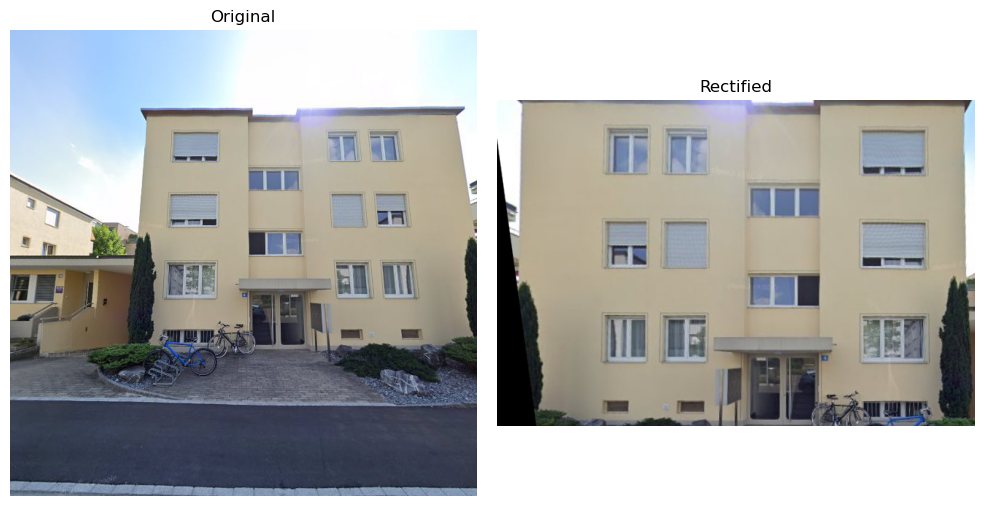

In [6]:
# -----------------------------------------------------------------------------
# Load the selected facade and scale predictions
# -----------------------------------------------------------------------------

selected_row = get_vlm_row_by_image_name(VLM_PREDICTIONS_CSV, TARGET_IMAGE_NAME)
selected_rectified_path = image_name_to_rectified_path(TARGET_IMAGE_NAME, RECTIFIED_DIR)
selected_original_path = IMAGES_DIR / TARGET_IMAGE_NAME

W_M = float(selected_row["pred_width_m"])
H_M = float(selected_row["pred_height_m"])
FLOORS = int(selected_row["pred_floors"]) if pd.notna(selected_row.get("pred_floors")) else None

RECTIFIED_BGR = read_image_bgr(selected_rectified_path)
H_PX, W_PX = RECTIFIED_BGR.shape[:2]

PX_PER_M_X = W_PX / W_M
PX_PER_M_Y = H_PX / H_M

summary_df = pd.DataFrame(
    [{
        "selected_image": TARGET_IMAGE_NAME,
        "rectified_image": selected_row.get("rectified_image"),
        "rectified_path": str(selected_rectified_path),
        "original_path": str(selected_original_path),
        "pred_width_m": W_M,
        "pred_height_m": H_M,
        "pred_floors": FLOORS,
        "rectified_width_px": W_PX,
        "rectified_height_px": H_PX,
        "px_per_m_x": PX_PER_M_X,
        "px_per_m_y": PX_PER_M_Y,
        "parse_status": selected_row.get("parse_status"),
        "provider": selected_row.get("provider"),
        "model_name": selected_row.get("model_name"),
    }]
)

display(summary_df)

if SHOW_VISUALS:
    show_images_row(
        [("Original", selected_original_path), ("Rectified", selected_rectified_path)],
        figsize_scale=5
    )

In [7]:
# -----------------------------------------------------------------------------
# Geometry loading and reprojection helpers
# -----------------------------------------------------------------------------

def load_geometry_for_image_name(results_csv: str | Path, image_name: str):
    df = pd.read_csv(results_csv)

    stem = Path(image_name).stem
    facade_id, version_num = stem.rsplit("_v", 1)
    facade_version = f"v{version_num}"

    row = df[(df["facade_id"] == facade_id) & (df["facade_version"] == facade_version)].iloc[0]

    k_cols = [f"K{i}{j}" for i in (1, 2, 3) for j in (1, 2, 3)]
    rt_cols = [f"Rt{i}{j}" for i in (1, 2, 3) for j in (1, 2, 3, 4)]

    geom = dict(
        K_scaled=row[k_cols].astype(float).to_numpy().reshape(3, 3),
        Rt=row[rt_cols].astype(float).to_numpy().reshape(3, 4),
        plane_origin=row[["po_x", "po_y", "po_z"]].astype(float).to_numpy(),
        h_dir=row[["h_x", "h_y", "h_z"]].astype(float).to_numpy(),
        v_dir=row[["v_x", "v_y", "v_z"]].astype(float).to_numpy(),
        min_x=float(row["min_x"]),
        max_x=float(row["max_x"]),
        min_y=float(row["min_y"]),
        max_y=float(row["max_y"]),
        W_pred=int(row["W_pred"]),
        H_pred=int(row["H_pred"]),
    )

    meta = dict(
        facade_id=facade_id,
        facade_version=facade_version,
        H_orig=int(row["H_orig"]),
        W_orig=int(row["W_orig"]),
    )
    return geom, meta


def unrectify_facade(
    rectified_img_path: str | Path,
    out_path: str | Path,
    original_shape: tuple[int, int],
    K_scaled: np.ndarray,
    Rt: np.ndarray,
    plane_origin: np.ndarray,
    h_dir: np.ndarray,
    v_dir: np.ndarray,
    min_x: float,
    max_x: float,
    min_y: float,
    max_y: float,
    W_pred: int,
    H_pred: int,
    blend_with_original: str | Path | None = None,
    flip_horizontal: bool = True,
) -> Path:
    rect = read_image_rgb(rectified_img_path)
    H_img, W_img = original_shape

    K_inv = np.linalg.inv(K_scaled)
    R_wc = Rt[:, :3].T
    t_wc = -Rt[:, :3].T @ Rt[:, 3]

    n = np.cross(h_dir, v_dir)
    n /= np.linalg.norm(n)

    ys, xs = np.indices((H_img, W_img), dtype=np.float32)
    pix_h = np.stack([xs, ys, np.ones_like(xs)], axis=-1)

    d_cam = (K_inv @ pix_h.reshape(-1, 3).T).T
    d_world = (R_wc @ d_cam.T).T

    cam_pos = t_wc
    numer = (plane_origin - cam_pos) @ n
    t_param = numer / (d_world @ n + 1e-12)
    pts_world = cam_pos + d_world * t_param[:, None]

    vec = pts_world - plane_origin
    x_plane = vec @ h_dir
    y_plane = vec @ v_dir

    x_norm = (x_plane - min_x) / (max_x - min_x)
    y_norm = (y_plane - min_y) / (max_y - min_y)

    u_rect = x_norm * (W_pred - 1)
    v_rect = y_norm * (H_pred - 1)

    map_x = u_rect.reshape((H_img, W_img)).astype(np.float32)
    map_y = v_rect.reshape((H_img, W_img)).astype(np.float32)

    reproj = cv2.remap(
        rect,
        map_x,
        map_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT,
        borderValue=(0, 0, 0),
    )

    if blend_with_original is not None:
        base = read_image_rgb(blend_with_original)
        mask = ((map_x >= 0) & (map_x < W_pred - 1) & (map_y >= 0) & (map_y < H_pred - 1))
        reproj = np.where(mask[..., None], reproj, base)

    if flip_horizontal:
        reproj = cv2.flip(reproj, 1)

    out_path = Path(out_path)
    cv2.imwrite(str(out_path), cv2.cvtColor(reproj, cv2.COLOR_RGB2BGR))
    return out_path


GEOM, GEOM_META = load_geometry_for_image_name(RECTIFICATION_RESULTS_CSV, TARGET_IMAGE_NAME)
print(GEOM_META)

{'facade_id': '151360_0', 'facade_version': 'v1', 'H_orig': 640, 'W_orig': 640}


In [8]:
# -----------------------------------------------------------------------------
# Layout helpers
# -----------------------------------------------------------------------------

MODULES = {
    "L": [1.3, 0.935, 225],
    "Q": [1.3, 0.72, 165],
    "M": [0.875, 0.935, 150],
    "S": [0.875, 0.72, 110],
    "C": [1.0, 1.7, 400],
}

CLASSES = [
    "unknown", "background", "facade", "window", "door", "cornice",
    "sill", "balcony", "blind", "molding", "deco", "pillar", "shop"
]
ID2LABEL = {i: c for i, c in enumerate(CLASSES)}
LABEL2ID = {c: i for i, c in ID2LABEL.items()}


@dataclass
class AutoPVConfig:
    device: str = "cuda"
    img_size: int = 640
    model_ckpt_ade20k: str = "nvidia/segformer-b5-finetuned-ade-640-640"
    trained_weights: Optional[str] = None
    selected_module: str = "L"
    gap_m: float = 0.02
    obstacle_buffer_m: float = 0.10
    edge_margin_m: float = 0.05
    alignment_for_gemini: bool = True

    @property
    def panel_w_m(self) -> float:
        return MODULES[self.selected_module][0]

    @property
    def panel_h_m(self) -> float:
        return MODULES[self.selected_module][1]

    @property
    def module_power_w(self) -> float:
        return MODULES[self.selected_module][2]


def pick_panel_anchor_with_opencv(image_path: str | Path) -> tuple[float, float]:
    image_path = Path(image_path)
    img_bgr = read_image_bgr(image_path)
    h, w = img_bgr.shape[:2]

    clicked = {"x": None, "y": None}
    window_name = "Click the top-left anchor for the PV grid"

    def mouse_callback(event, x, y, flags, param):
        if event == cv2.EVENT_LBUTTONDOWN:
            clicked["x"] = x
            clicked["y"] = y

    cv2.namedWindow(window_name, cv2.WINDOW_NORMAL)
    cv2.setMouseCallback(window_name, mouse_callback)

    while True:
        display = img_bgr.copy()
        if clicked["x"] is not None and clicked["y"] is not None:
            cv2.drawMarker(display, (clicked["x"], clicked["y"]), color=(0, 0, 255), markerType=cv2.MARKER_CROSS, markerSize=20, thickness=2)
            rel = (clicked["x"] / w, clicked["y"] / h)
            text = f"rel=({rel[0]:.4f}, {rel[1]:.4f})"
            cv2.putText(display, text, (20, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2, cv2.LINE_AA)

        cv2.imshow(window_name, display)
        key = cv2.waitKey(20) & 0xFF
        if key in (13, 32) and clicked["x"] is not None and clicked["y"] is not None:
            break
        if key == 27:
            cv2.destroyWindow(window_name)
            raise ValueError("Selection cancelled by user.")

    cv2.destroyWindow(window_name)
    return clicked["x"] / w, clicked["y"] / h


def overlay_texture_on_panel_boxes(
    rectified_img_path: str | Path,
    panel_boxes: list[tuple[int, int, int, int]],
    texture_path: str | Path,
    out_path: str | Path,
    alpha: float = 0.9,
) -> Path:
    img_rgb = read_image_rgb(rectified_img_path)
    tex_rgb = read_image_rgb(texture_path)
    composite = img_rgb.copy()

    for x0, y0, x1, y1 in panel_boxes:
        roi_w = x1 - x0
        roi_h = y1 - y0
        tex_resized = cv2.resize(tex_rgb, (roi_w, roi_h), interpolation=cv2.INTER_LINEAR)
        roi = composite[y0:y1, x0:x1]
        composite[y0:y1, x0:x1] = cv2.addWeighted(roi, 1 - alpha, tex_resized, alpha, 0)

    out_path = Path(out_path)
    cv2.imwrite(str(out_path), cv2.cvtColor(composite, cv2.COLOR_RGB2BGR))
    return out_path


def build_panel_boxes_from_manual_layout(
    image_shape: tuple[int, int],
    panel_size_px: tuple[int, int],
    grid_shape: tuple[int, int],
    top_left_rel: tuple[float, float],
    col_direction: str,
    row_direction: str,
) -> list[tuple[int, int, int, int]]:
    h_img, w_img = image_shape
    rows, cols = grid_shape
    panel_w_px, panel_h_px = panel_size_px

    step_map = {
        "right": (panel_w_px, 0),
        "left": (-panel_w_px, 0),
        "down": (0, panel_h_px),
        "up": (0, -panel_h_px),
    }

    col_step = step_map[col_direction.lower()]
    row_step = step_map[row_direction.lower()]

    x0 = int(round(w_img * top_left_rel[0]))
    y0 = int(round(h_img * top_left_rel[1]))

    boxes = []
    for r in range(rows):
        for c in range(cols):
            tl_x = x0 + c * col_step[0] + r * row_step[0]
            tl_y = y0 + c * col_step[1] + r * row_step[1]
            br_x = tl_x + panel_w_px
            br_y = tl_y + panel_h_px
            if tl_x < 0 or tl_y < 0 or br_x > w_img or br_y > h_img:
                continue
            boxes.append((tl_x, tl_y, br_x, br_y))
    return boxes


def boxes_to_mask(shape_hw: tuple[int, int], boxes: list[tuple[int, int, int, int]]) -> np.ndarray:
    h_img, w_img = shape_hw
    mask = np.zeros((h_img, w_img), dtype=np.uint8)
    for x0, y0, x1, y1 in boxes:
        cv2.rectangle(mask, (x0, y0), (x1, y1), 255, -1)
    return mask


def run_manual_layout(
    rectified_img_path: str | Path,
    image_name: str,
    csv_dimensions: str | Path,
    output_paths: dict[str, Path],
    cfg: dict,
) -> dict:
    rectified_rgb = read_image_rgb(rectified_img_path)
    h_img, w_img = rectified_rgb.shape[:2]
    row = get_vlm_row_by_image_name(csv_dimensions, image_name)
    real_w_m = float(row["pred_width_m"])
    real_h_m = float(row["pred_height_m"])
    px_per_m = (w_img / real_w_m + h_img / real_h_m) / 2.0

    top_left_rel = cfg["top_left_rel"]
    if cfg.get("interactive_anchor_picker", False):
        top_left_rel = pick_panel_anchor_with_opencv(rectified_img_path)

    panel_w_px = int(round(cfg["panel_size_m"][0] * px_per_m))
    panel_h_px = int(round(cfg["panel_size_m"][1] * px_per_m))

    boxes = build_panel_boxes_from_manual_layout(
        image_shape=(h_img, w_img),
        panel_size_px=(panel_w_px, panel_h_px),
        grid_shape=cfg["grid_shape"],
        top_left_rel=top_left_rel,
        col_direction=cfg["col_direction"],
        row_direction=cfg["row_direction"],
    )

    mask = boxes_to_mask((h_img, w_img), boxes)
    cv2.imwrite(str(output_paths["mask"]), mask)

    overlay_texture_on_panel_boxes(
        rectified_img_path=rectified_img_path,
        panel_boxes=boxes,
        texture_path=PV_TEXTURE_PNG,
        out_path=output_paths["overlay"],
        alpha=cfg["alpha"],
    )

    return {
        "layout_mode": "manual",
        "mask": mask,
        "panel_boxes": boxes,
        "panel_count": len(boxes),
        "top_left_rel": top_left_rel,
        "grid_shape": cfg["grid_shape"],
        "panel_size_m": cfg["panel_size_m"],
        "output_paths": output_paths,
    }


def preprocess_for_segformer(img_bgr: np.ndarray, size: int = 640) -> tuple[np.ndarray, tuple[int, int]]:
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    img_resized = cv2.resize(img_rgb, (size, size), interpolation=cv2.INTER_LINEAR)
    chw = np.transpose(img_resized, (2, 0, 1))
    return chw, img_bgr.shape[:2]


def build_segformer_model(cfg: AutoPVConfig):
    import torch
    from transformers import SegformerConfig, SegformerForSemanticSegmentation

    conf = SegformerConfig.from_pretrained(cfg.model_ckpt_ade20k)
    conf.num_labels = len(CLASSES)
    conf.id2label = ID2LABEL
    conf.label2id = LABEL2ID

    model = SegformerForSemanticSegmentation.from_pretrained(
        cfg.model_ckpt_ade20k,
        config=conf,
        ignore_mismatched_sizes=True,
    )

    if cfg.trained_weights and Path(cfg.trained_weights).exists():
        state = torch.load(cfg.trained_weights, map_location="cpu")
        model.load_state_dict(state, strict=False)
    elif cfg.trained_weights:
        print(f"Warning: trained SegFormer weights not found: {cfg.trained_weights}")
        print("Falling back to the pretrained checkpoint only.")

    device = cfg.device if torch.cuda.is_available() or cfg.device == "cpu" else "cpu"
    model.to(device).eval()
    cfg.device = device
    return model


def predict_segmentation_mask(img_bgr: np.ndarray, model, device: str, size: int) -> np.ndarray:
    import torch

    x, (h, w) = preprocess_for_segformer(img_bgr, size=size)
    inp = torch.from_numpy(x).unsqueeze(0).to(device)
    logits = model(pixel_values=inp).logits
    up = torch.nn.functional.interpolate(logits, size=(size, size), mode="bilinear", align_corners=False)
    pred = up.argmax(1)[0].detach().cpu().numpy().astype(np.uint8)
    pred_back = cv2.resize(pred, (w, h), interpolation=cv2.INTER_NEAREST)
    return pred_back


def pv_clean_from_pred_scaled(
    mask_np: np.ndarray,
    px_per_m_x: float,
    px_per_m_y: float,
    buffer_m: float = 0.10,
    edge_m: float = 0.05,
    min_blob_m2: float = 0.0,
) -> np.ndarray:
    wall_id = LABEL2ID["facade"]
    winshop_ids = [LABEL2ID["window"], LABEL2ID["shop"]]
    rest_ids = [
        LABEL2ID["door"], LABEL2ID["balcony"], LABEL2ID["cornice"],
        LABEL2ID["sill"], LABEL2ID["molding"], LABEL2ID["deco"],
        LABEL2ID["pillar"], LABEL2ID["blind"],
    ]

    wall = mask_np == wall_id
    obstacles = np.isin(mask_np, winshop_ids + rest_ids)

    if buffer_m > 0:
        rx = max(1, int(round(buffer_m * px_per_m_x)))
        ry = max(1, int(round(buffer_m * px_per_m_y)))
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * rx + 1, 2 * ry + 1))
        obstacles = cv2.dilate(obstacles.astype(np.uint8), k).astype(bool)

    pv = wall & (~obstacles)

    if edge_m > 0:
        ex = max(1, int(round(edge_m * px_per_m_x)))
        ey = max(1, int(round(edge_m * px_per_m_y)))
        k = cv2.getStructuringElement(cv2.MORPH_RECT, (2 * ex + 1, 2 * ey + 1))
        pv = cv2.erode(pv.astype(np.uint8), k).astype(bool)

    if min_blob_m2 > 0:
        px_per_m2 = px_per_m_x * px_per_m_y
        min_blob_px = int(round(min_blob_m2 * px_per_m2))
        num, lab, stats, _ = cv2.connectedComponentsWithStats(pv.astype(np.uint8), connectivity=8)
        keep = np.zeros_like(pv, dtype=bool)
        for i in range(1, num):
            if stats[i, cv2.CC_STAT_AREA] >= max(1, min_blob_px):
                keep |= lab == i
        pv = keep

    return pv.astype(np.uint8)


def largest_rectangle_in_binary_mask(mask: np.ndarray) -> tuple[int, int, int, int]:
    h, w = mask.shape
    heights = np.zeros((h, w), dtype=np.int32)
    for i in range(h):
        heights[i] = mask[i] if i == 0 else (heights[i - 1] + 1) * mask[i]

    best_area, best_rect = 0, (0, 0, 0, 0)

    for i in range(h):
        hrow = heights[i]
        stack = []
        j = 0
        while j <= w:
            cur_h = hrow[j] if j < w else 0
            if not stack or cur_h >= hrow[stack[-1]]:
                stack.append(j)
                j += 1
            else:
                top = stack.pop()
                height = hrow[top]
                left = stack[-1] + 1 if stack else 0
                width = j - left
                area = height * width
                if area > best_area:
                    best_area = area
                    best_rect = (left, i - height + 1, width, height)
    return best_rect


def pack_modules_in_rect(
    rect: tuple[int, int, int, int],
    w_px: int,
    h_px: int,
    w_m: float,
    h_m: float,
    panel_w_m: float,
    panel_h_m: float,
    gap_m: float,
) -> dict:
    x, y, w, h = rect
    if w_m <= 0 or h_m <= 0 or w <= 0 or h <= 0:
        return {"orientation": "none", "nx": 0, "ny": 0, "count": 0, "used_w": 0, "used_h": 0, "pw": 0, "ph": 0, "gap": 0}

    sx = w_px / w_m
    sy = h_px / h_m

    pw_p = max(1, int(round(panel_w_m * sx)))
    ph_p = max(1, int(round(panel_h_m * sy)))
    pw_l = max(1, int(round(panel_h_m * sx)))
    ph_l = max(1, int(round(panel_w_m * sy)))
    gapx = max(1, int(round(gap_m * sx)))

    def pack(rect_w, rect_h, pw, ph, gap):
        nx = max(int(math.floor((rect_w + gap) / (pw + gap))), 0)
        ny = max(int(math.floor((rect_h + gap) / (ph + gap))), 0)
        used_w = nx * pw + (nx - 1) * gap if nx > 0 else 0
        used_h = ny * ph + (ny - 1) * gap if ny > 0 else 0
        return nx, ny, used_w, used_h, nx * ny

    nx_p, ny_p, uw_p, uh_p, n_p = pack(w, h, pw_p, ph_p, gapx)
    nx_l, ny_l, uw_l, uh_l, n_l = pack(w, h, pw_l, ph_l, gapx)

    leftover_p = (w * h) - (uw_p * uh_p)
    leftover_l = (w * h) - (uw_l * uh_l)

    if (n_p > n_l) or (n_p == n_l and leftover_p < leftover_l):
        return {"orientation": "portrait", "nx": nx_p, "ny": ny_p, "count": n_p, "used_w": uw_p, "used_h": uh_p, "pw": pw_p, "ph": ph_p, "gap": gapx}

    return {"orientation": "landscape", "nx": nx_l, "ny": ny_l, "count": n_l, "used_w": uw_l, "used_h": uh_l, "pw": pw_l, "ph": ph_l, "gap": gapx}


def build_layout_mask_and_boxes(shape_hw: tuple[int, int], rect: tuple[int, int, int, int], pack: dict) -> tuple[np.ndarray, list[tuple[int, int, int, int]]]:
    h_img, w_img = shape_hw
    x, y, w, h = rect

    mask = np.zeros((h_img, w_img), dtype=np.uint8)
    boxes = []

    nx, ny = pack["nx"], pack["ny"]
    pw, ph = pack["pw"], pack["ph"]
    gap = pack["gap"]
    used_w, used_h = pack["used_w"], pack["used_h"]

    x_start = x + max(0, (w - used_w) // 2)
    y_start = y + max(0, (h - used_h) // 2)

    for row in range(ny):
        for col in range(nx):
            x0 = x_start + col * (pw + gap)
            y0 = y_start + row * (ph + gap)
            x1 = min(x0 + pw, w_img)
            y1 = min(y0 + ph, h_img)
            boxes.append((x0, y0, x1, y1))
            cv2.rectangle(mask, (x0, y0), (x1, y1), 255, -1)

    return mask, boxes


def run_automatic_layout(
    rectified_img_path: str | Path,
    rectified_bgr: np.ndarray,
    output_paths: dict[str, Path],
    w_px: int,
    h_px: int,
    w_m: float,
    h_m: float,
    px_per_m_x: float,
    px_per_m_y: float,
    cfg: AutoPVConfig,
) -> dict:
    seg_model = build_segformer_model(cfg)
    pred_mask = predict_segmentation_mask(rectified_bgr, seg_model, cfg.device, cfg.img_size)

    panel_area_m2 = cfg.panel_w_m * cfg.panel_h_m
    pv_suitable_mask = pv_clean_from_pred_scaled(
        pred_mask,
        px_per_m_x=px_per_m_x,
        px_per_m_y=px_per_m_y,
        buffer_m=cfg.obstacle_buffer_m,
        edge_m=cfg.edge_margin_m,
        min_blob_m2=panel_area_m2,
    )

    largest_rect = largest_rectangle_in_binary_mask(pv_suitable_mask.astype(bool))
    auto_pack = pack_modules_in_rect(
        rect=largest_rect,
        w_px=w_px,
        h_px=h_px,
        w_m=w_m,
        h_m=h_m,
        panel_w_m=cfg.panel_w_m,
        panel_h_m=cfg.panel_h_m,
        gap_m=cfg.gap_m,
    )

    layout_mask, panel_boxes = build_layout_mask_and_boxes((h_px, w_px), largest_rect, auto_pack)
    cv2.imwrite(str(output_paths["mask"]), layout_mask)

    overlay_texture_on_panel_boxes(
        rectified_img_path=rectified_img_path,
        panel_boxes=panel_boxes,
        texture_path=PV_TEXTURE_PNG,
        out_path=output_paths["overlay"],
        alpha=0.90,
    )

    return {
        "layout_mode": "automatic",
        "pred_mask": pred_mask,
        "pv_suitable_mask": pv_suitable_mask,
        "largest_rect": largest_rect,
        "packing": auto_pack,
        "mask": layout_mask,
        "panel_boxes": panel_boxes,
        "panel_count": len(panel_boxes),
        "panel_size_m": (cfg.panel_w_m, cfg.panel_h_m),
        "module_power_w": cfg.module_power_w,
        "output_paths": output_paths,
    }

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/segformer-b5-finetuned-ade-640-640 and are newly initialized because the shapes did not match:
- decode_head.classifier.weight: found shape torch.Size([150, 768, 1, 1]) in the checkpoint and torch.Size([13, 768, 1, 1]) in the model instantiated
- decode_head.classifier.bias: found shape torch.Size([150]) in the checkpoint and torch.Size([13]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
C:\Users\durana\AppData\Local\Temp\ipykernel_7828\1268168869.py:227: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details

,image_name,layout_mode,variant_name,panel_count,mask_path,overlay_path
0,151360_0_v1.jpg,automatic,automatic_gemini,8,D:\facade2dim\image2bipv\outputs\2_generated_b...,D:\facade2dim\image2bipv\outputs\2_generated_b...


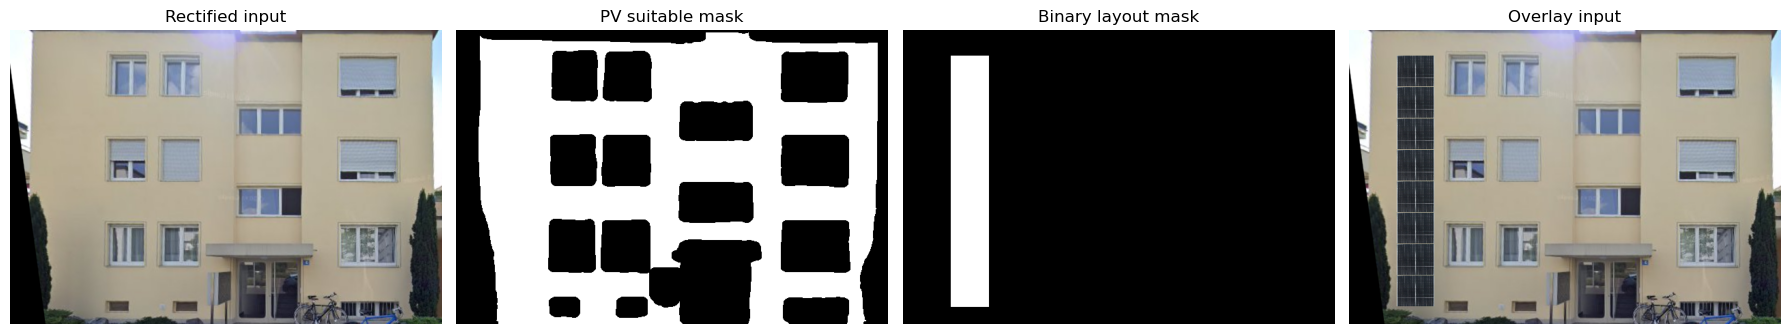

In [9]:
# -----------------------------------------------------------------------------
# Build the selected layout
# -----------------------------------------------------------------------------

VARIANT_NAME = build_variant_name(LAYOUT_MODE, GENERATOR_TYPE, GENERATE_APPEARANCE)
OUTPUT_PATHS = build_bipv_output_paths(TARGET_IMAGE_NAME, VARIANT_NAME)

if LAYOUT_MODE == "manual":
    layout_result = run_manual_layout(
        rectified_img_path=selected_rectified_path,
        image_name=TARGET_IMAGE_NAME,
        csv_dimensions=VLM_PREDICTIONS_CSV,
        output_paths=OUTPUT_PATHS,
        cfg=MANUAL_LAYOUT_CONFIG,
    )
else:
    auto_cfg = AutoPVConfig(
        device="cuda" if os.environ.get("CUDA_VISIBLE_DEVICES", "") != "" or True else "cpu",
        img_size=AUTO_LAYOUT_CONFIG["img_size"],
        model_ckpt_ade20k=AUTO_LAYOUT_CONFIG["segformer_checkpoint"],
        trained_weights=str(AUTO_LAYOUT_CONFIG["segformer_weights"]),
        selected_module=AUTO_LAYOUT_CONFIG["selected_module"],
        gap_m=AUTO_LAYOUT_CONFIG["gap_m"],
        obstacle_buffer_m=AUTO_LAYOUT_CONFIG["obstacle_buffer_m"],
        edge_margin_m=AUTO_LAYOUT_CONFIG["edge_margin_m"],
        alignment_for_gemini=AUTO_LAYOUT_CONFIG["alignment_for_gemini"],
    )

    layout_result = run_automatic_layout(
        rectified_img_path=selected_rectified_path,
        rectified_bgr=RECTIFIED_BGR,
        output_paths=OUTPUT_PATHS,
        w_px=W_PX,
        h_px=H_PX,
        w_m=W_M,
        h_m=H_M,
        px_per_m_x=PX_PER_M_X,
        px_per_m_y=PX_PER_M_Y,
        cfg=auto_cfg,
    )

layout_summary = {
    "image_name": TARGET_IMAGE_NAME,
    "layout_mode": LAYOUT_MODE,
    "variant_name": VARIANT_NAME,
    "panel_count": int(layout_result["panel_count"]),
    "mask_path": str(OUTPUT_PATHS["mask"]),
    "overlay_path": str(OUTPUT_PATHS["overlay"]),
}
display(pd.DataFrame([layout_summary]))

if SHOW_VISUALS:
    visuals = [("Rectified input", selected_rectified_path)]
    if "pv_suitable_mask" in layout_result:
        visuals.append(("PV suitable mask", layout_result["pv_suitable_mask"] * 255))
    visuals.extend([
        ("Binary layout mask", OUTPUT_PATHS["mask"]),
        ("Overlay input", OUTPUT_PATHS["overlay"]),
    ])
    show_images_row(visuals, figsize_scale=4.5)

In [10]:
# -----------------------------------------------------------------------------
# Appearance-generation helpers
# -----------------------------------------------------------------------------

def load_controlnet_pipeline():
    import torch
    from diffusers import ControlNetModel, AutoencoderKL, StableDiffusionXLControlNetInpaintPipeline

    dtype = torch.float16
    device = "cuda" if torch.cuda.is_available() else "cpu"

    controlnet_model = ControlNetModel.from_pretrained(
        "diffusers/controlnet-canny-sdxl-1.0",
        torch_dtype=dtype,
        use_safetensors=True,
    )

    vae_model = AutoencoderKL.from_pretrained(
        "madebyollin/sdxl-vae-fp16-fix",
        torch_dtype=dtype,
        use_safetensors=True,
    )

    pipe = StableDiffusionXLControlNetInpaintPipeline.from_pretrained(
        "stabilityai/stable-diffusion-xl-base-1.0",
        controlnet=controlnet_model,
        vae=vae_model,
        torch_dtype=dtype,
        use_safetensors=True,
    )

    if device == "cuda":
        pipe.enable_model_cpu_offload()
    else:
        pipe.to(device)

    pipe.safety_checker = None
    return pipe, device


def run_controlnet_generation(
    facade_png: str | Path,
    mask_png: str | Path,
    out_png: str | Path,
    canny_png: str | Path,
    prompt: str = CONTROLNET_PROMPT,
    negative_prompt: str = CONTROLNET_NEGATIVE_PROMPT,
    canny_low: int = 5,
    canny_high: int = 25,
    controlnet_scale: float = 0.5,
    num_inference_steps: int = 30,
    seed: int | None = None,
    show: bool = True,
) -> dict:
    import torch

    pipe, device = load_controlnet_pipeline()

    init_img = pil_rgb(facade_png)
    mask_img = pil_gray(mask_png)

    np_img = np.array(init_img)
    edges = cv2.Canny(np_img, canny_low, canny_high)
    canny_rgb = Image.fromarray(np.repeat(edges[:, :, None], 3, axis=2))

    generator = None
    if seed is not None:
        generator = torch.Generator(device=device).manual_seed(seed)

    t0 = perf_counter()
    result_img = pipe(
        prompt=prompt,
        negative_prompt=negative_prompt,
        image=init_img,
        mask_image=mask_img,
        control_image=canny_rgb,
        controlnet_conditioning_scale=controlnet_scale,
        num_inference_steps=num_inference_steps,
        generator=generator,
    ).images[0]
    duration_sec = perf_counter() - t0

    out_png = Path(out_png)
    out_png.parent.mkdir(parents=True, exist_ok=True)
    result_img.save(out_png)

    canny_png = Path(canny_png)
    canny_rgb.save(canny_png)

    if show:
        show_images_row(
            [
                ("Overlay input", np.array(init_img)),
                ("Binary mask", np.array(mask_img)),
                ("Canny", np.array(canny_rgb)),
                ("Generated image", np.array(result_img)),
            ],
            figsize_scale=4,
        )

    return {
        "generator": "controlnet",
        "generated_rectified_path": out_png,
        "generated_raw_path": out_png,
        "canny_path": canny_png,
        "duration_sec": duration_sec,
    }


def run_gemini_image_edit(
    image_path: str | Path,
    out_path: str | Path,
    prompt: str = GEMINI_EDIT_PROMPT,
    model_name: str = GEMINI_MODEL_NAME,
    api_key_env: str = "GOOGLE_API_KEY",
    show: bool = True,
) -> dict:
    from google import genai
    from google.genai import types

    client = genai.Client(api_key=require_env(api_key_env))
    image_input = Image.open(image_path).convert("RGB")

    t0 = perf_counter()
    response = client.models.generate_content(
        model=model_name,
        contents=[image_input, prompt],
        config=types.GenerateContentConfig(response_modalities=["Image"]),
    )
    duration_sec = perf_counter() - t0

    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)

    saved = False
    text_parts = []
    for part in response.parts:
        if getattr(part, "text", None):
            text_parts.append(part.text)
        elif getattr(part, "inline_data", None) is not None:
            image = part.as_image()
            image.save(out_path)
            saved = True
            break

    if not saved:
        raise RuntimeError("Gemini returned no image part.")

    if show:
        show_images_row(
            [
                ("Overlay input", image_path),
                ("Generated image", out_path),
            ],
            figsize_scale=4.5,
        )

    return {
        "generator": "gemini",
        "generated_raw_path": out_path,
        "duration_sec": duration_sec,
        "text_response": "\n".join(text_parts).strip(),
    }


def align_and_merge_gemini_edit(
    original_rectified_path: str | Path,
    gemini_img_path: str | Path,
    pv_mask_path: str | Path,
    out_path: str | Path,
    aligned_out_path: str | Path,
    expand_mask_px: int = 3,
    blur_mask_px: int = 9,
    motion_model: int = cv2.MOTION_HOMOGRAPHY,
    ecc_iterations: int = 300,
    ecc_eps: float = 1e-6,
    do_alignment: bool = True,
    show: bool = True,
) -> dict:
    original_bgr = read_image_bgr(original_rectified_path)
    gemini_bgr = read_image_bgr(gemini_img_path)
    mask = cv2.imread(str(pv_mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(pv_mask_path)

    h, w = original_bgr.shape[:2]
    gemini_init = cv2.resize(gemini_bgr, (w, h), interpolation=cv2.INTER_LINEAR)

    aligned_gemini = gemini_init
    warp_matrix = None

    if do_alignment:
        original_gray = cv2.cvtColor(original_bgr, cv2.COLOR_BGR2GRAY)
        gemini_gray = cv2.cvtColor(gemini_init, cv2.COLOR_BGR2GRAY)

        warp_matrix = np.eye(3, 3, dtype=np.float32) if motion_model == cv2.MOTION_HOMOGRAPHY else np.eye(2, 3, dtype=np.float32)
        criteria = (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, ecc_iterations, ecc_eps)

        try:
            _, warp_matrix = cv2.findTransformECC(
                templateImage=original_gray,
                inputImage=gemini_gray,
                warpMatrix=warp_matrix,
                motionType=motion_model,
                criteria=criteria,
                inputMask=None,
                gaussFiltSize=5,
            )

            if motion_model == cv2.MOTION_HOMOGRAPHY:
                aligned_gemini = cv2.warpPerspective(
                    gemini_init,
                    warp_matrix,
                    (w, h),
                    flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP,
                    borderMode=cv2.BORDER_REFLECT,
                )
            else:
                aligned_gemini = cv2.warpAffine(
                    gemini_init,
                    warp_matrix,
                    (w, h),
                    flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP,
                    borderMode=cv2.BORDER_REFLECT,
                )
        except cv2.error as e:
            print("ECC alignment failed. Falling back to resized Gemini output.")
            print("OpenCV:", e)

    mask_bin = (mask > 0).astype(np.uint8) * 255

    if expand_mask_px > 0:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * expand_mask_px + 1, 2 * expand_mask_px + 1))
        mask_bin = cv2.dilate(mask_bin, k, iterations=1)

    if blur_mask_px > 0:
        blur_mask_px = blur_mask_px if blur_mask_px % 2 == 1 else blur_mask_px + 1
        mask_soft = cv2.GaussianBlur(mask_bin, (blur_mask_px, blur_mask_px), 0).astype(np.float32) / 255.0
    else:
        mask_soft = mask_bin.astype(np.float32) / 255.0

    mask_soft_3 = np.repeat(mask_soft[:, :, None], 3, axis=2)

    original_f = original_bgr.astype(np.float32)
    aligned_f = aligned_gemini.astype(np.float32)
    merged = np.clip(original_f * (1.0 - mask_soft_3) + aligned_f * mask_soft_3, 0, 255).astype(np.uint8)

    out_path = Path(out_path)
    aligned_out_path = Path(aligned_out_path)
    cv2.imwrite(str(out_path), merged)
    cv2.imwrite(str(aligned_out_path), aligned_gemini)

    if show:
        show_images_row(
            [
                ("Original rectified", cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)),
                ("Gemini raw", cv2.cvtColor(gemini_bgr, cv2.COLOR_BGR2RGB)),
                ("Gemini aligned", cv2.cvtColor(aligned_gemini, cv2.COLOR_BGR2RGB)),
                ("Merged rectified", cv2.cvtColor(merged, cv2.COLOR_BGR2RGB)),
            ],
            figsize_scale=4,
        )

    return {
        "generated_rectified_path": out_path,
        "generated_aligned_path": aligned_out_path,
        "warp_matrix": warp_matrix,
        "alignment_used": do_alignment,
    }

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


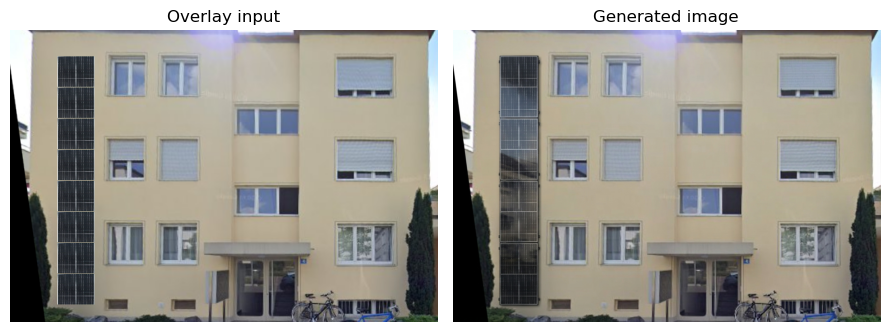

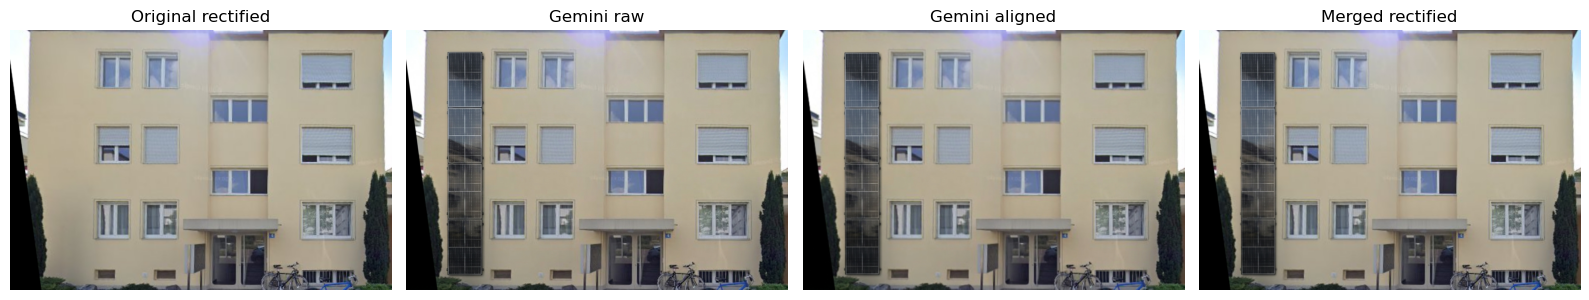

,generate_appearance,generator_type,generated_rectified_path
0,True,gemini,D:\facade2dim\image2bipv\outputs\2_generated_b...


In [11]:
# -----------------------------------------------------------------------------
# Optional appearance generation
# -----------------------------------------------------------------------------

generation_result = None

if GENERATE_APPEARANCE and GENERATOR_TYPE == "controlnet":
    generation_result = run_controlnet_generation(
        facade_png=OUTPUT_PATHS["overlay"],
        mask_png=OUTPUT_PATHS["mask"],
        out_png=OUTPUT_PATHS["generated_rectified"],
        canny_png=OUTPUT_PATHS["canny"],
        seed=GLOBAL_SEED,
        show=SHOW_VISUALS,
    )

elif GENERATE_APPEARANCE and GENERATOR_TYPE == "gemini":
    raw_result = run_gemini_image_edit(
        image_path=OUTPUT_PATHS["overlay"],
        out_path=OUTPUT_PATHS["generated_raw"],
        prompt=GEMINI_EDIT_PROMPT,
        model_name=GEMINI_MODEL_NAME,
        show=SHOW_VISUALS,
    )

    use_alignment = AUTO_LAYOUT_CONFIG.get("alignment_for_gemini", True) if LAYOUT_MODE == "automatic" else False

    merged_result = align_and_merge_gemini_edit(
        original_rectified_path=selected_rectified_path,
        gemini_img_path=raw_result["generated_raw_path"],
        pv_mask_path=OUTPUT_PATHS["mask"],
        out_path=OUTPUT_PATHS["generated_rectified"],
        aligned_out_path=OUTPUT_PATHS["generated_aligned"],
        do_alignment=use_alignment,
        show=SHOW_VISUALS,
    )

    generation_result = {
        **raw_result,
        **merged_result,
    }

else:
    print("Skipping appearance generation. Mask and overlay outputs are ready.")

generation_summary = pd.DataFrame(
    [{
        "generate_appearance": GENERATE_APPEARANCE,
        "generator_type": GENERATOR_TYPE,
        "generated_rectified_path": None if generation_result is None else str(generation_result.get("generated_rectified_path")),
    }]
)
display(generation_summary)

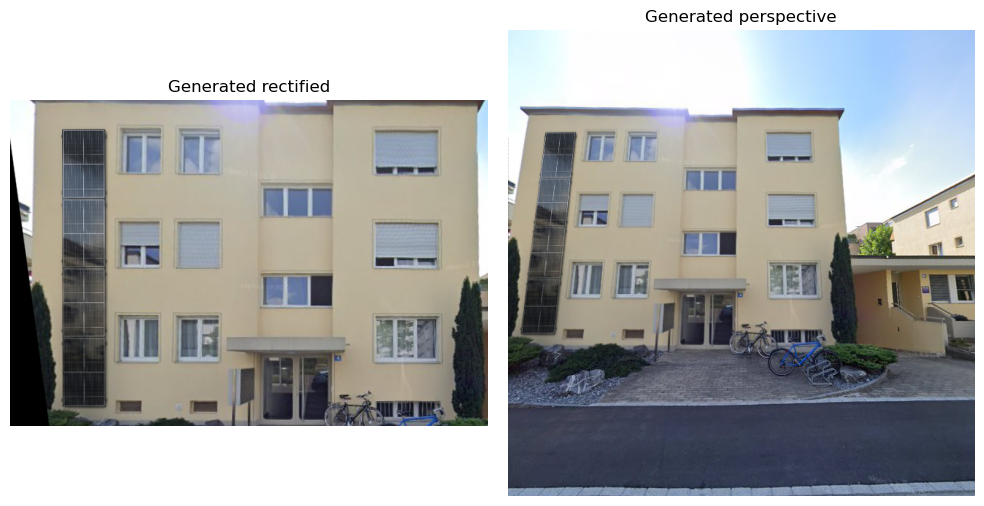

In [12]:
# -----------------------------------------------------------------------------
# Optional reprojection back to the original perspective
# -----------------------------------------------------------------------------

generated_perspective_path = None

if GENERATE_APPEARANCE and REPROJECT_TO_PERSPECTIVE and generation_result is not None:
    generated_perspective_path = unrectify_facade(
        rectified_img_path=generation_result["generated_rectified_path"],
        out_path=OUTPUT_PATHS["generated_perspective"],
        original_shape=(GEOM_META["H_orig"], GEOM_META["W_orig"]),
        blend_with_original=selected_original_path,
        **GEOM,
    )

    if SHOW_VISUALS:
        show_images_row(
            [
                ("Generated rectified", generation_result["generated_rectified_path"]),
                ("Generated perspective", generated_perspective_path),
            ],
            figsize_scale=5,
        )
else:
    print("Skipping perspective reprojection.")

In [13]:
# -----------------------------------------------------------------------------
# Persist run summary
# -----------------------------------------------------------------------------

run_record = {
    "image_name": TARGET_IMAGE_NAME,
    "layout_mode": LAYOUT_MODE,
    "generator_type": GENERATOR_TYPE,
    "generate_appearance": GENERATE_APPEARANCE,
    "variant_name": VARIANT_NAME,
    "mask_path": str(OUTPUT_PATHS["mask"]),
    "overlay_path": str(OUTPUT_PATHS["overlay"]),
    "panel_count": int(layout_result["panel_count"]),
    "panel_size_m": str(layout_result.get("panel_size_m")),
    "generated_rectified_path": None if generation_result is None else str(generation_result.get("generated_rectified_path")),
    "generated_perspective_path": None if generated_perspective_path is None else str(generated_perspective_path),
    "prompt": GEMINI_EDIT_PROMPT if GENERATOR_TYPE == "gemini" else CONTROLNET_PROMPT if GENERATOR_TYPE == "controlnet" else None,
}

log_df = append_run_record(run_record, RUN_LOG_CSV)
display(pd.DataFrame([run_record]))
print(f"Run log updated: {RUN_LOG_CSV}")
print(f"Total logged runs: {len(log_df)}")

,image_name,layout_mode,generator_type,generate_appearance,variant_name,mask_path,overlay_path,panel_count,panel_size_m,generated_rectified_path,generated_perspective_path,prompt
0,151360_0_v1.jpg,automatic,gemini,True,automatic_gemini,D:\facade2dim\image2bipv\outputs\2_generated_b...,D:\facade2dim\image2bipv\outputs\2_generated_b...,8,"(1.3, 0.935)",D:\facade2dim\image2bipv\outputs\2_generated_b...,D:\facade2dim\image2bipv\outputs\2_generated_b...,make the PV panels on the facade look more rea...


Run log updated: D:\facade2dim\image2bipv\outputs\2_generated_bipv_facades\tables\generation_runtime_log.csv
Total logged runs: 1
